# Notebook 04 — Exploratory Data Analysis (EDA)

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

INPUT_PATH = PROJECT_ROOT / "data" / "processed" / "online_food_delivery_analysis_featured.csv"

if not INPUT_PATH.exists():
    raise FileNotFoundError(
        "Featured dataset not found. Run Notebook 03 and confirm that "
        "data/processed/online_food_delivery_analysis_featured.csv exists."
    )

df = pd.read_csv(INPUT_PATH)
print("Dataset shape:", df.shape)
display(df.head())
display(df.dtypes.rename("Data_Type").to_frame())


Dataset shape: (100000, 42)


,Order_ID,Customer_ID,Customer_Age,Customer_Gender,City,Area,Restaurant_ID,Restaurant_Name,Cuisine_Type,Order_Date,...,Peak_Period,Peak_Hour_Recalculated,Customer_Age_Group,Delivery_Performance,Discount_Percentage,Profit_Margin_Percentage,Order_Value_Band,Is_Cancelled,Is_Delivered,Is_Non_Delivered
0,ORD000001,CUST03987,24.0,Male,Chennai,OMR,RES1298,Restaurant_1298,Fast Food,2024-06-05,...,Off-Peak,False,18–25,Slow,5.259836,2.9,"1,001–2,000",0,1,0
1,ORD000002,CUST01917,45.0,Female,Hyderabad,NaN,RES1191,Restaurant_1191,Chinese,2024-05-11,...,Off-Peak,False,36–45,Standard,4.083466,21.4,Up to 500,0,1,0
2,ORD000003,CUST13338,57.0,Male,Bengaluru,Indiranagar,RES0681,Restaurant_0681,Indian,2024-02-02,...,Off-Peak,False,46–60,Slow,0.000000,20.4,Up to 500,0,1,0
3,ORD000004,CUST09787,66.0,Female,Chennai,Velachery,RES0453,Restaurant_0453,Indian,2024-03-27,...,Evening Peak,True,Over 60,Standard,6.838261,29.3,"501–1,000",0,1,0
4,ORD000005,CUST15793,43.0,Female,Chennai,Anna Nagar,RES0268,Restaurant_0268,Indian,2024-07-11,...,Morning Peak,True,36–45,NaN,17.486492,NaN,"501–1,000",0,0,1


,Data_Type
Order_ID,str
Customer_ID,str
Customer_Age,float64
Customer_Gender,str
City,str
Area,str
Restaurant_ID,str
Restaurant_Name,str
Cuisine_Type,str
Order_Date,str


## 1. Data readiness and key metrics

In [2]:
status = df["Order_Status"].astype("string").str.strip().str.casefold()
is_delivered = status.eq("delivered")
is_cancelled = status.eq("cancelled")

total_orders = len(df)
delivered_orders = int(is_delivered.sum())
cancelled_orders = int(is_cancelled.sum())
known_delivered_amount = is_delivered & pd.to_numeric(df["Final_Amount"], errors="coerce").notna()

total_revenue = pd.to_numeric(df.loc[known_delivered_amount, "Final_Amount"], errors="coerce").sum()
aov = (
    total_revenue / int(known_delivered_amount.sum())
    if int(known_delivered_amount.sum()) > 0 else np.nan
)
cancellation_rate = cancelled_orders / total_orders * 100 if total_orders else np.nan
avg_delivery_time = pd.to_numeric(
    df.loc[is_delivered, "Delivery_Time_Min"], errors="coerce"
).mean()
avg_delivery_rating = pd.to_numeric(
    df.loc[is_delivered, "Delivery_Rating"], errors="coerce"
).mean()
avg_restaurant_rating = pd.to_numeric(
    df.loc[is_delivered, "Restaurant_Rating"], errors="coerce"
).mean()
avg_profit_margin_pct = pd.to_numeric(
    df.loc[is_delivered, "Profit_Margin"], errors="coerce"
).mean() * 100

kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Orders", "Delivered Orders", "Cancelled Orders",
        "Revenue from Delivered Orders", "Average Order Value",
        "Cancellation Rate (%)", "Average Delivery Time (minutes)",
        "Average Delivery Rating", "Average Restaurant Rating",
        "Average Profit Margin (%)"
    ],
    "Value": [
        total_orders, delivered_orders, cancelled_orders,
        total_revenue, aov, cancellation_rate, avg_delivery_time,
        avg_delivery_rating, avg_restaurant_rating, avg_profit_margin_pct
    ]
})
display(kpi_summary)


,Metric,Value
0,Total Orders,1.000000e+05
1,Delivered Orders,8.928800e+04
2,Cancelled Orders,6.143000e+03
3,Revenue from Delivered Orders,8.915816e+07
4,Average Order Value,1.008451e+03
5,Cancellation Rate (%),6.143000e+00
6,Average Delivery Time (minutes),6.149635e+01
7,Average Delivery Rating,4.177004e+00
8,Average Restaurant Rating,4.086835e+00
9,Average Profit Margin (%),1.763996e+01


## 2. Order status distribution

,Orders
Order_Status,
Delivered,89288
Cancelled,6143
Out for Delivery,2541
Preparing,2028


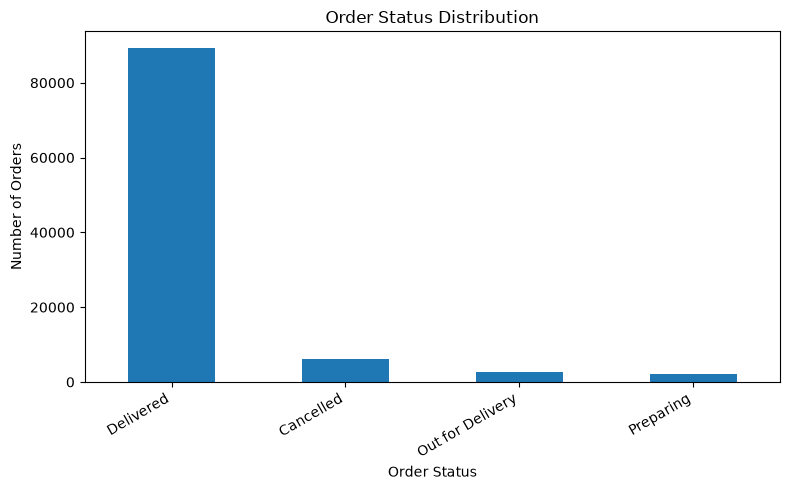

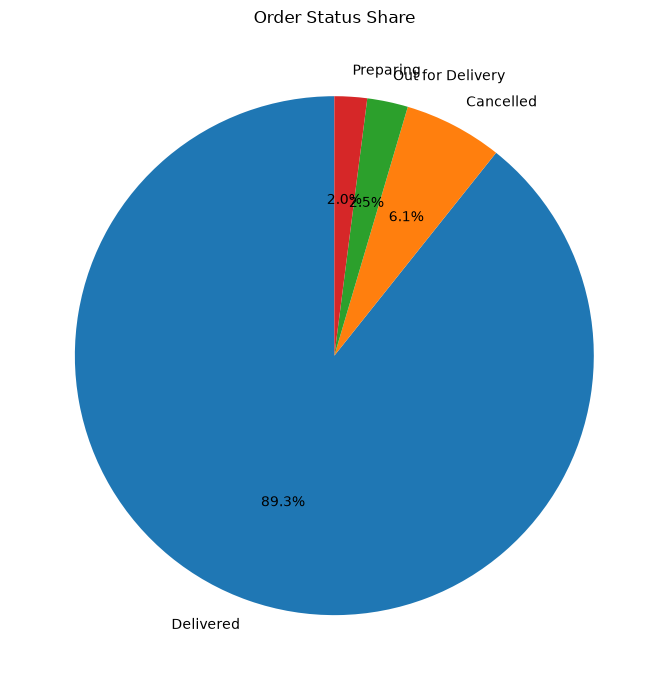

In [3]:
status_counts = df["Order_Status"].value_counts(dropna=False)
display(status_counts.rename_axis("Order_Status").to_frame("Orders"))

plt.figure(figsize=(8, 5))
status_counts.plot(kind="bar")
plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 7))
status_counts.plot(kind="pie", autopct="%1.1f%%", startangle=90)
plt.title("Order Status Share")
plt.ylabel("")
plt.tight_layout()
plt.show()


## 3. Order trends over time

,Orders
Order_Month_Period,
2024-01,8409
2024-02,7951
2024-03,8485
2024-04,8195
2024-05,8365
2024-06,8089
2024-07,8470
2024-08,8587
2024-09,8175


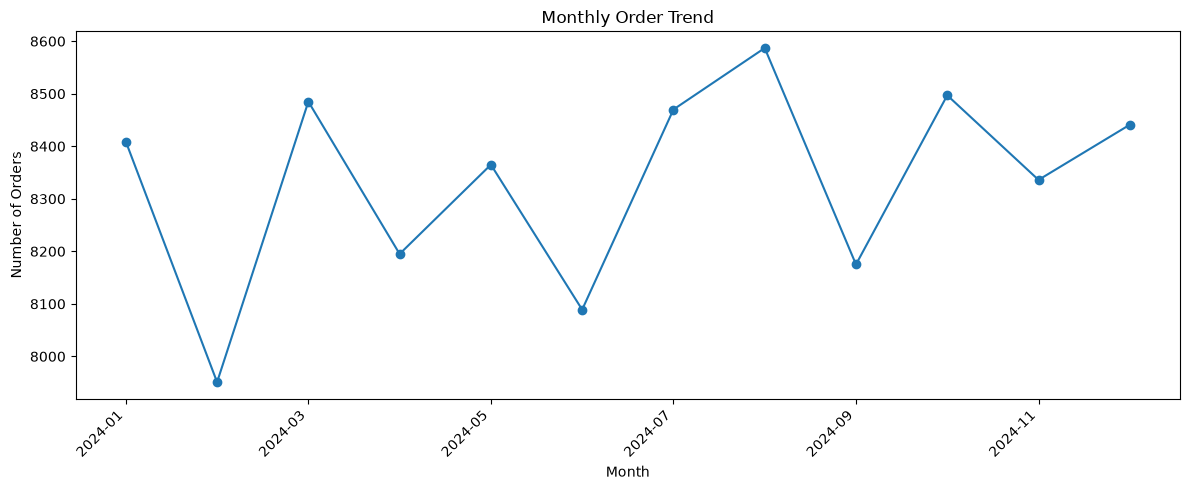

,Orders
Order_Weekday_Name,
Monday,14521
Tuesday,14334
Wednesday,14208
Thursday,14261
Friday,14271
Saturday,14198
Sunday,14207


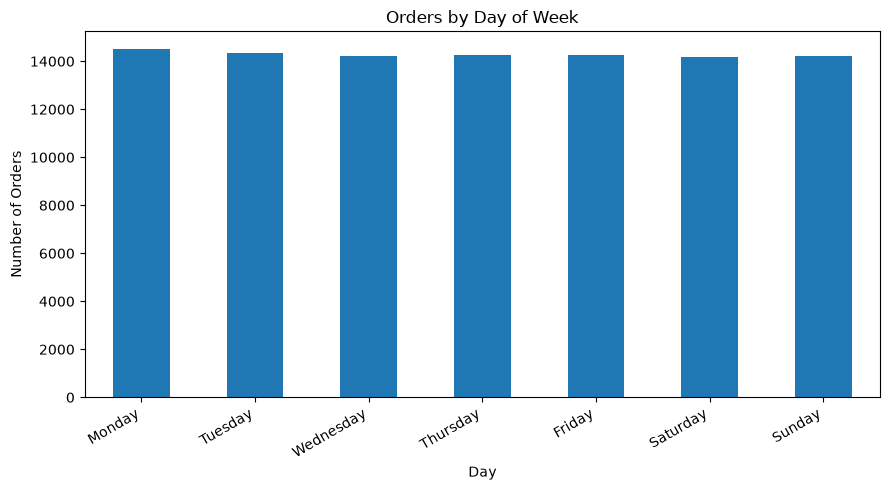

In [4]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")
df["Order_Month_Period"] = df["Order_Date"].dt.to_period("M").astype("string")
monthly_orders = df.groupby("Order_Month_Period", dropna=False).size().rename("Orders")
display(monthly_orders.to_frame())

plt.figure(figsize=(12, 5))
monthly_orders.plot(kind="line", marker="o")
plt.title("Monthly Order Trend")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

weekday_order = df["Order_Weekday_Name"].value_counts().reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
)
display(weekday_order.rename("Orders").to_frame())

plt.figure(figsize=(9, 5))
weekday_order.plot(kind="bar")
plt.title("Orders by Day of Week")
plt.xlabel("Day")
plt.ylabel("Number of Orders")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


## 4. Peak-hour analysis

,Orders
Order_Hour,
0,4174
1,4138
2,4262
3,4111
4,4234
5,4209
6,4273
7,4206
8,4107


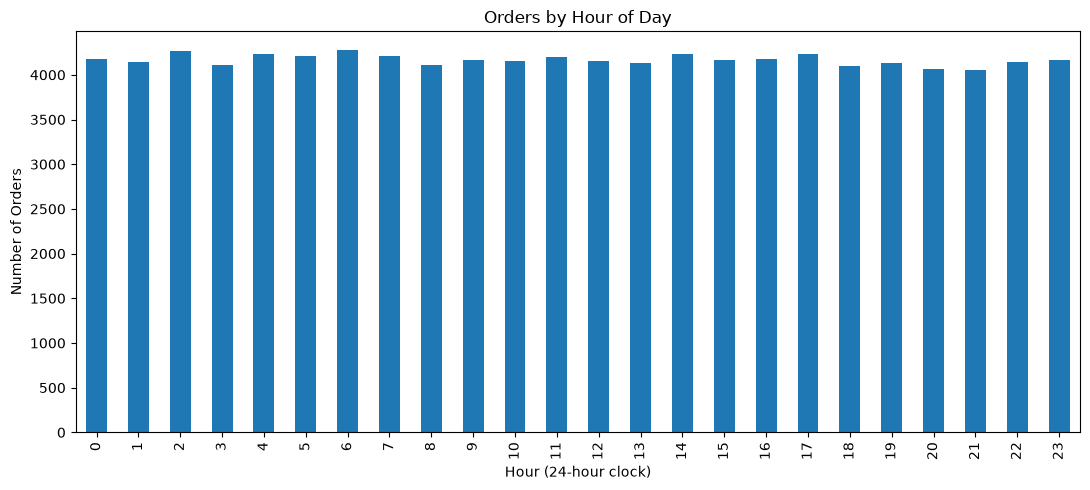

,Orders
Peak_Period,
Off-Peak,62872
Evening Peak,16359
Morning Peak,12484
Lunch Peak,8285


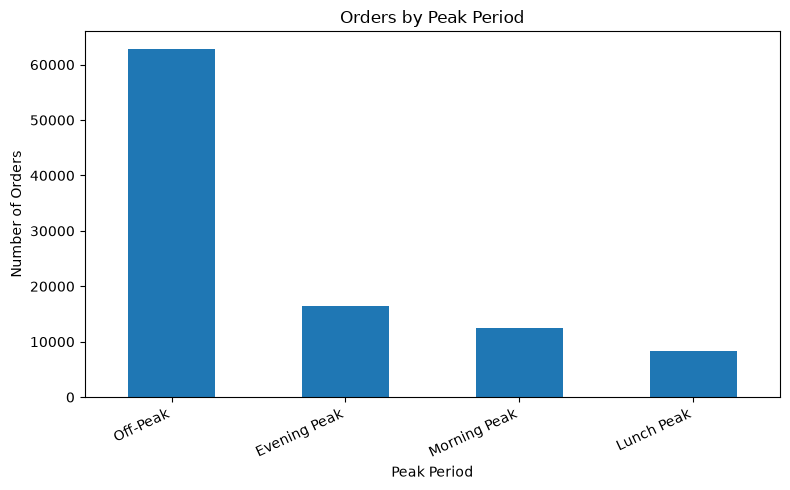

In [5]:
hourly_orders = df["Order_Hour"].value_counts(dropna=False).sort_index()
display(hourly_orders.rename("Orders").to_frame())

plt.figure(figsize=(11, 5))
hourly_orders.dropna().plot(kind="bar")
plt.title("Orders by Hour of Day")
plt.xlabel("Hour (24-hour clock)")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

if "Peak_Period" in df.columns:
    peak_counts = df["Peak_Period"].value_counts(dropna=False)
    display(peak_counts.rename("Orders").to_frame())

    plt.figure(figsize=(8, 5))
    peak_counts.plot(kind="bar")
    plt.title("Orders by Peak Period")
    plt.xlabel("Peak Period")
    plt.ylabel("Number of Orders")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()


## 5. Revenue and order value analysis

,Recorded_Revenue,Orders_With_Amount,Average_Final_Amount
City,,,
Chennai,19604968.04,19397,1010.721660
Bengaluru,15952450.64,15750,1012.854009
Mumbai,15010169.56,14935,1005.033114
Hyderabad,11365309.33,11278,1007.741561
Delhi,10769573.05,10702,1006.314058
Pune,8786219.33,8792,999.342508
Kolkata,7197296.83,7073,1017.573424


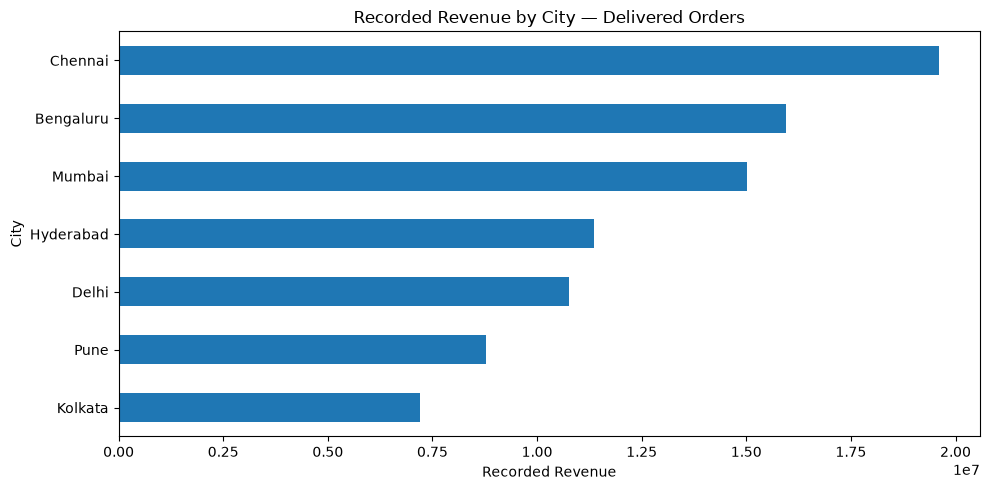

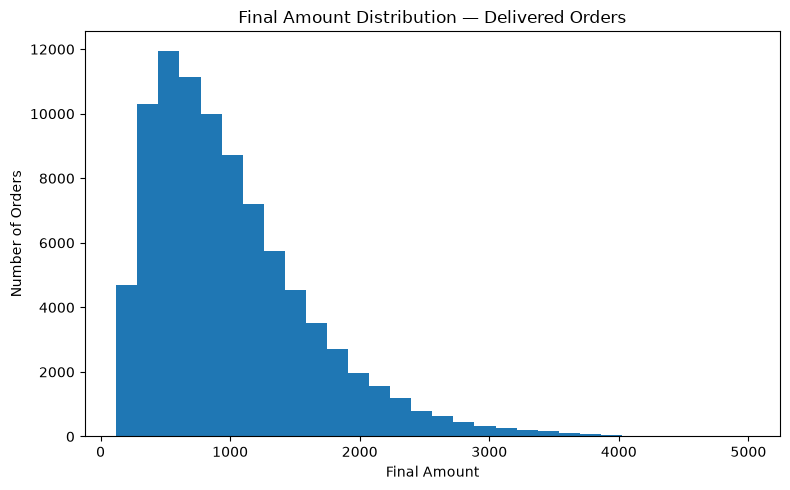

In [6]:
df["Final_Amount"] = pd.to_numeric(df["Final_Amount"], errors="coerce")
df["Order_Value"] = pd.to_numeric(df["Order_Value"], errors="coerce")

revenue_by_city = (
    df.loc[is_delivered & df["Final_Amount"].notna()]
      .groupby("City")["Final_Amount"]
      .agg(["sum", "count", "mean"])
      .sort_values("sum", ascending=False)
      .rename(columns={"sum": "Recorded_Revenue", "count": "Orders_With_Amount", "mean": "Average_Final_Amount"})
)
display(revenue_by_city)

plt.figure(figsize=(10, 5))
revenue_by_city["Recorded_Revenue"].sort_values().plot(kind="barh")
plt.title("Recorded Revenue by City — Delivered Orders")
plt.xlabel("Recorded Revenue")
plt.ylabel("City")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
df.loc[is_delivered, "Final_Amount"].dropna().plot(kind="hist", bins=30)
plt.title("Final Amount Distribution — Delivered Orders")
plt.xlabel("Final Amount")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()


## 6. Customer demographics


Customer_Age_Group distribution:


,Orders
Customer_Age_Group,
46–60,27937
26–35,18683
36–45,18499
Over 60,18462
18–25,14943
NaN,1476



Customer_Gender distribution:


,Orders
Customer_Gender,
Female,46685
Male,46420
Prefer not to say,3940
Non-binary,1965
NaN,990



City distribution:


,Orders
City,
Chennai,21880
Bengaluru,17906
Mumbai,16889
Hyderabad,12777
Delhi,12150
Pune,9909
Kolkata,7941
NaN,548


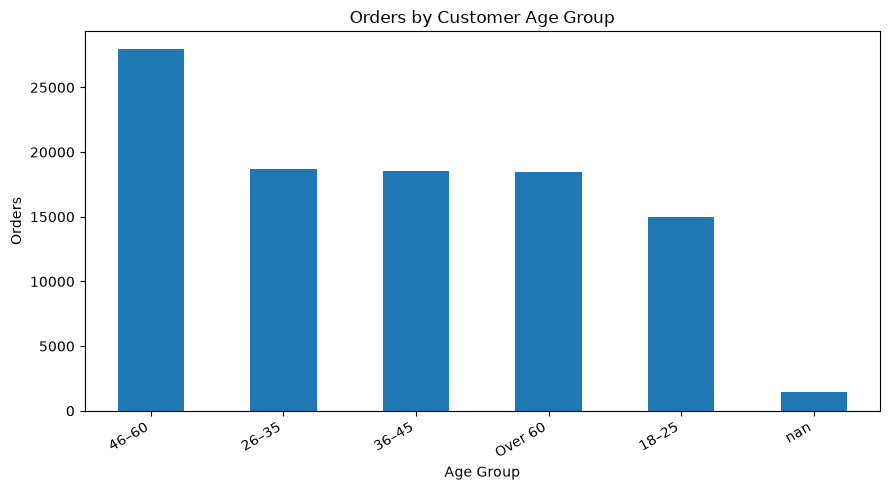

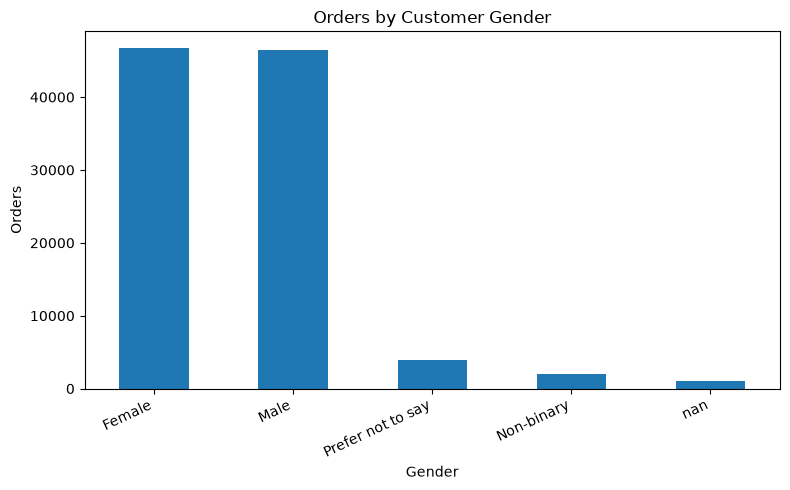

In [7]:
for column in ["Customer_Age_Group", "Customer_Gender", "City"]:
    if column in df.columns:
        counts = df[column].value_counts(dropna=False)
        print(f"\n{column} distribution:")
        display(counts.rename("Orders").to_frame())

plt.figure(figsize=(9, 5))
df["Customer_Age_Group"].value_counts(dropna=False).plot(kind="bar")
plt.title("Orders by Customer Age Group")
plt.xlabel("Age Group")
plt.ylabel("Orders")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
df["Customer_Gender"].value_counts(dropna=False).plot(kind="bar")
plt.title("Orders by Customer Gender")
plt.xlabel("Gender")
plt.ylabel("Orders")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


## 7. Cuisine and restaurant performance

,Delivered_Orders_With_Amount,Recorded_Revenue,Average_Final_Amount,Average_Delivery_Time,Average_Delivery_Rating
Cuisine_Type,,,,,
Indian,17757,17922156.71,1009.300935,63.064988,4.161957
South Indian,14054,14260888.30,1014.720955,63.008894,4.162645
Fast Food,13392,13610330.93,1016.303086,59.904719,4.197600
Chinese,10641,10663679.99,1002.131378,63.060803,4.154130
Italian,7083,7144852.83,1008.732575,60.112805,4.187091
Arabian,5314,5347260.52,1006.259037,60.041588,4.197177
Thai,5302,5318594.47,1003.129851,60.529046,4.197756
Healthy,5211,5267730.45,1010.886672,60.037037,4.185366
Desserts,5248,5161777.60,983.570427,60.133003,4.182836


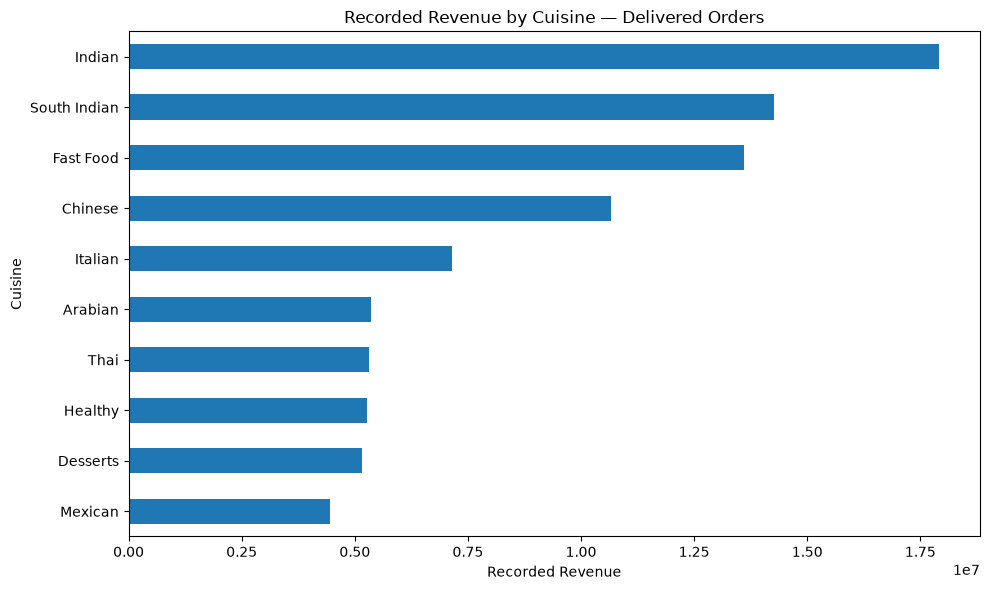

Top 10 restaurants by recorded revenue:


,,Delivered_Orders_With_Amount,Recorded_Revenue,Average_Final_Amount,Average_Restaurant_Rating,Average_Delivery_Time
Restaurant_ID,Restaurant_Name,,,,,
RES0542,Restaurant_0542,86,90246.65,1049.379651,4.071429,58.395349
RES0280,Restaurant_0280,74,89965.98,1215.756486,4.064286,61.472973
RES0590,Restaurant_0590,73,89200.07,1221.918767,3.949296,57.246575
RES1252,Restaurant_1252,78,88183.79,1130.561410,4.106579,61.064103
RES1195,Restaurant_1195,86,88166.00,1025.186047,4.044706,56.488372
RES0561,Restaurant_0561,83,86751.24,1045.195663,4.020482,62.614458
RES0271,Restaurant_0271,82,86747.62,1057.897805,4.070513,59.073171
RES0760,Restaurant_0760,75,85370.35,1138.271333,4.020270,61.080000
RES1177,Restaurant_1177,78,84349.86,1081.408462,4.072727,57.756410


In [8]:
delivered_with_amount = df.loc[is_delivered & df["Final_Amount"].notna()].copy()

cuisine_performance = (
    delivered_with_amount.groupby("Cuisine_Type")
    .agg(
        Delivered_Orders_With_Amount=("Order_ID", "count"),
        Recorded_Revenue=("Final_Amount", "sum"),
        Average_Final_Amount=("Final_Amount", "mean"),
        Average_Delivery_Time=("Delivery_Time_Min", "mean"),
        Average_Delivery_Rating=("Delivery_Rating", "mean")
    )
    .sort_values("Recorded_Revenue", ascending=False)
)
display(cuisine_performance)

plt.figure(figsize=(10, 6))
cuisine_performance["Recorded_Revenue"].sort_values().plot(kind="barh")
plt.title("Recorded Revenue by Cuisine — Delivered Orders")
plt.xlabel("Recorded Revenue")
plt.ylabel("Cuisine")
plt.tight_layout()
plt.show()

restaurant_performance = (
    delivered_with_amount.groupby(["Restaurant_ID", "Restaurant_Name"], dropna=False)
    .agg(
        Delivered_Orders_With_Amount=("Order_ID", "count"),
        Recorded_Revenue=("Final_Amount", "sum"),
        Average_Final_Amount=("Final_Amount", "mean"),
        Average_Restaurant_Rating=("Restaurant_Rating", "mean"),
        Average_Delivery_Time=("Delivery_Time_Min", "mean")
    )
    .sort_values(
    ["Recorded_Revenue", "Delivered_Orders_With_Amount"],
    ascending=False
)
)
print("Top 10 restaurants by recorded revenue:")
display(restaurant_performance.head(10))


## 8. Delivery performance and distance

Delivery time summary for delivered orders:


,Delivery_Time_Min
count,89288.000000
mean,61.496349
std,19.671650
min,12.000000
25%,48.000000
50%,59.000000
75%,72.000000
max,150.000000


,Orders,Average_Distance_km,Average_Delivery_Time_Min
Distance_Band,,,
0–2 km,4568,1.475799,40.881786
>2–5 km,21289,3.583387,46.858659
>5–10 km,32638,7.312178,57.172498
>10 km,29604,15.429223,79.952202


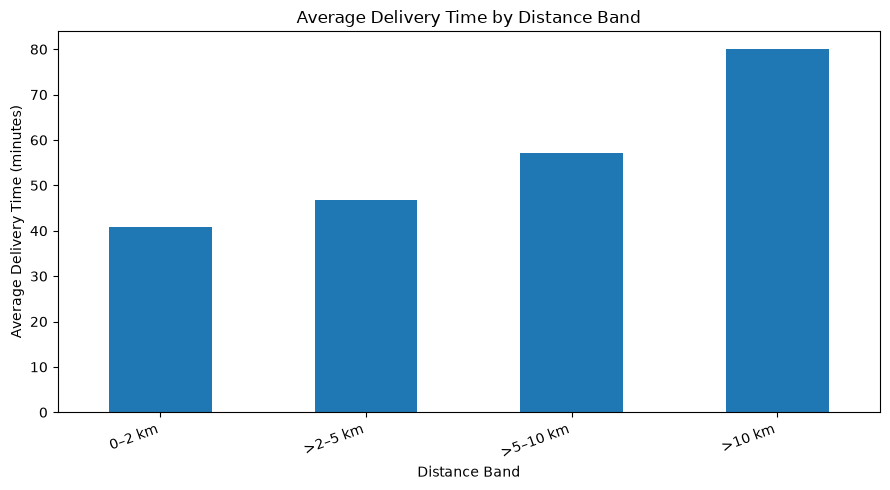

,Orders
Delivery_Performance,
Standard,46759
Slow,40700
Fast,1829


In [9]:
delivered = df.loc[is_delivered].copy()
delivered["Delivery_Time_Min"] = pd.to_numeric(delivered["Delivery_Time_Min"], errors="coerce")
delivered["Distance_km"] = pd.to_numeric(delivered["Distance_km"], errors="coerce")

print("Delivery time summary for delivered orders:")
display(delivered["Delivery_Time_Min"].describe().to_frame("Delivery_Time_Min"))

distance_valid = delivered.loc[delivered["Distance_km"].notna() & delivered["Delivery_Time_Min"].notna()].copy()
distance_valid["Distance_Band"] = pd.cut(
    distance_valid["Distance_km"],
    bins=[-np.inf, 2, 5, 10, np.inf],
    labels=["0–2 km", ">2–5 km", ">5–10 km", ">10 km"]
)
distance_summary = distance_valid.groupby("Distance_Band", observed=False).agg(
    Orders=("Order_ID", "count"),
    Average_Distance_km=("Distance_km", "mean"),
    Average_Delivery_Time_Min=("Delivery_Time_Min", "mean")
)
display(distance_summary)

plt.figure(figsize=(9, 5))
distance_summary["Average_Delivery_Time_Min"].plot(kind="bar")
plt.title("Average Delivery Time by Distance Band")
plt.xlabel("Distance Band")
plt.ylabel("Average Delivery Time (minutes)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

if "Delivery_Performance" in df.columns:
    display(df.loc[is_delivered, "Delivery_Performance"].value_counts(dropna=False).rename("Orders").to_frame())


## 9. Ratings and profit margin

,Delivery_Rating,Restaurant_Rating,Profit_Margin_Ratio
count,85621.000000,86970.000000,89288.000000
mean,4.177004,4.086835,0.176400
std,0.471978,0.527581,0.071728
min,1.400000,1.700000,-0.050000
25%,3.900000,3.700000,0.128000
50%,4.200000,4.100000,0.177000
75%,4.500000,4.500000,0.225000
max,5.000000,5.000000,0.380000


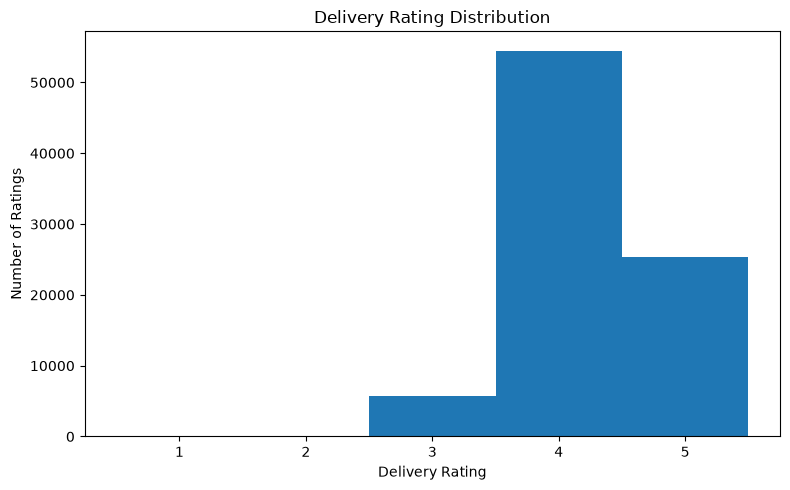

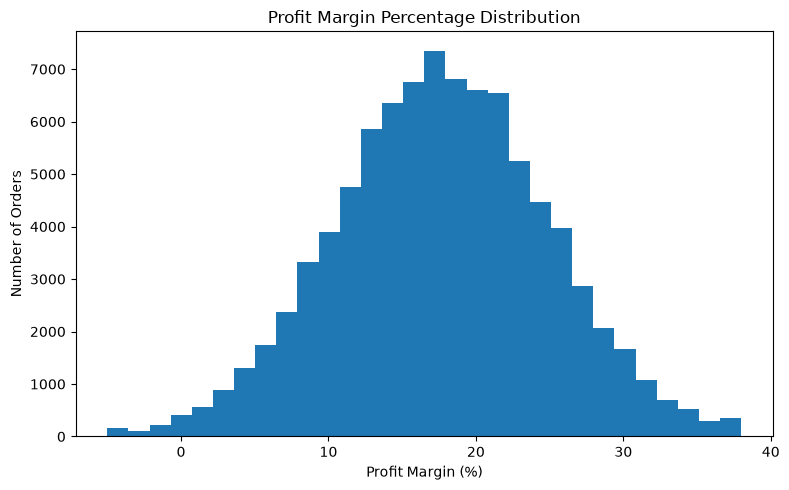

In [10]:
rating_margin_summary = pd.DataFrame({
    "Delivery_Rating": pd.to_numeric(df.loc[is_delivered, "Delivery_Rating"], errors="coerce").describe(),
    "Restaurant_Rating": pd.to_numeric(df.loc[is_delivered, "Restaurant_Rating"], errors="coerce").describe(),
    "Profit_Margin_Ratio": pd.to_numeric(df.loc[is_delivered, "Profit_Margin"], errors="coerce").describe()
})
display(rating_margin_summary)

plt.figure(figsize=(8, 5))
pd.to_numeric(df.loc[is_delivered, "Delivery_Rating"], errors="coerce").dropna().plot(kind="hist", bins=np.arange(0.5, 6.5, 1))
plt.title("Delivery Rating Distribution")
plt.xlabel("Delivery Rating")
plt.ylabel("Number of Ratings")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
(pd.to_numeric(df.loc[is_delivered, "Profit_Margin"], errors="coerce") * 100).dropna().plot(kind="hist", bins=30)
plt.title("Profit Margin Percentage Distribution")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()


## 10. Discounts and payment modes

In [11]:
payment_summary = df.groupby("Payment_Mode", dropna=False).agg(
    Orders=("Order_ID", "count"),
    Delivered_Orders=("Is_Delivered", "sum"),
    Cancelled_Orders=("Is_Cancelled", "sum"),
    Average_Order_Value=("Order_Value", "mean"),
    Average_Discount=("Discount_Applied", "mean")
).sort_values("Orders", ascending=False)
display(payment_summary)

discount_valid = df.loc[is_delivered & df["Discount_Applied"].notna() & df["Order_Value"].notna()].copy()
discount_valid["Discount_Percentage_Recalculated"] = np.where(
    discount_valid["Order_Value"] > 0,
    discount_valid["Discount_Applied"] / discount_valid["Order_Value"] * 100,
    np.nan
)
display(discount_valid[["Discount_Applied", "Order_Value", "Discount_Percentage_Recalculated"]].describe())


,Orders,Delivered_Orders,Cancelled_Orders,Average_Order_Value,Average_Discount
Payment_Mode,,,,,
UPI,41689,37223,2567,1086.022690,75.993340
Credit Card,22023,19685,1342,1086.823080,76.184839
Debit Card,15882,14153,971,1080.512166,76.256344
COD,11901,10628,751,1079.061014,76.106150
Wallet,8014,7159,482,1095.543398,75.763074
NaN,491,440,30,1036.965235,79.244376


,Discount_Applied,Order_Value,Discount_Percentage_Recalculated
count,88411.000000,88411.000000,88411.000000
mean,76.127488,1084.578523,9.086730
std,83.305165,626.530968,10.816229
min,0.000000,183.310000,0.000000
25%,0.000000,622.585000,0.000000
50%,50.000000,944.750000,4.947850
75%,115.655000,1393.385000,14.256455
max,300.000000,5000.000000,35.002375


## 11. Cancellation analysis

,Cancelled_Orders
Cancellation_Reason,
Restaurant Issue,1710
Customer Cancelled,1634
Rider Unavailable,1212
Incorrect Address,849
Payment Issue,738


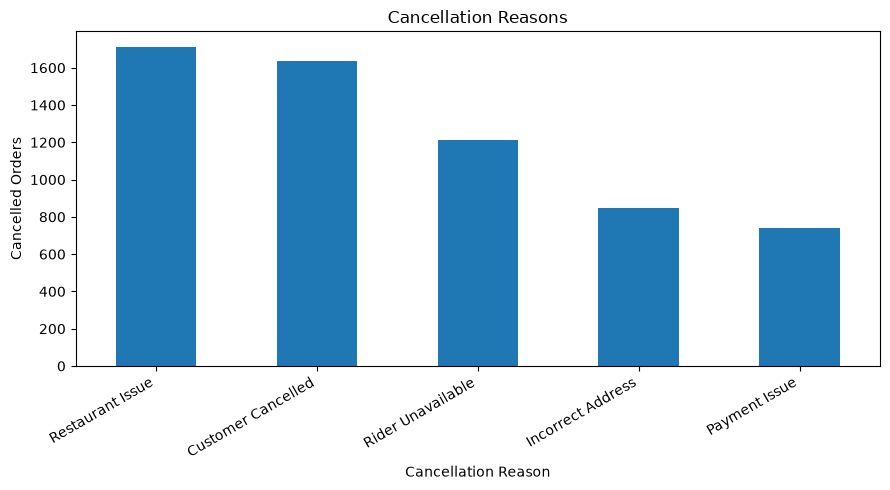

,Total_Orders,Cancelled_Orders,Cancellation_Rate_Percent
City,,,
NaN,548,38,6.934307
Delhi,12150,786,6.469136
Bengaluru,17906,1145,6.394505
Mumbai,16889,1049,6.211143
Hyderabad,12777,784,6.136026
Chennai,21880,1314,6.005484
Pune,9909,572,5.772530
Kolkata,7941,455,5.729757


In [12]:
cancelled = df.loc[is_cancelled].copy()
cancellation_reasons = cancelled["Cancellation_Reason"].value_counts(dropna=False)
display(cancellation_reasons.rename("Cancelled_Orders").to_frame())

plt.figure(figsize=(9, 5))
cancellation_reasons.plot(kind="bar")
plt.title("Cancellation Reasons")
plt.xlabel("Cancellation Reason")
plt.ylabel("Cancelled Orders")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

cancel_rate_by_city = df.groupby("City", dropna=False).agg(
    Total_Orders=("Order_ID", "count"),
    Cancelled_Orders=("Is_Cancelled", "sum")
)
cancel_rate_by_city["Cancellation_Rate_Percent"] = (
    cancel_rate_by_city["Cancelled_Orders"] / cancel_rate_by_city["Total_Orders"] * 100
)
display(cancel_rate_by_city.sort_values("Cancellation_Rate_Percent", ascending=False))


## 12. Export key EDA summary tables

In [13]:
EDA_DIR = PROJECT_ROOT / "outputs" / "eda"
EDA_DIR.mkdir(parents=True, exist_ok=True)

kpi_summary.to_csv(EDA_DIR / "eda_kpi_summary.csv", index=False)
revenue_by_city.to_csv(EDA_DIR / "revenue_by_city.csv")
cuisine_performance.to_csv(EDA_DIR / "cuisine_performance.csv")
restaurant_performance.head(50).to_csv(EDA_DIR / "top_50_restaurants.csv")
payment_summary.to_csv(EDA_DIR / "payment_mode_summary.csv")
cancel_rate_by_city.to_csv(EDA_DIR / "cancellation_rate_by_city.csv")

print("EDA summaries saved to:", EDA_DIR.resolve())
print("Files:")
for path in sorted(EDA_DIR.glob("*.csv")):
    print("-", path.name)


EDA summaries saved to: D:\online food delivery analysis final\outputs\eda
Files:
- cancellation_rate_by_city.csv
- cuisine_performance.csv
- eda_kpi_summary.csv
- payment_mode_summary.csv
- revenue_by_city.csv
- top_50_restaurants.csv
